# Time Series - Gelecek Ay Satış Tahmini (Predict Future Sales)

Bu projede Rus yazılım/oyun mağaza zinciri 1C Company'nin 2013 Ocak - 2015 Ekim arası günlük satış verisini kullanarak 2015 Kasım ayında her mağazada her ürünün kaç adet satılacağını tahmin edeceğiz.Zaman serisi problemini, geçmiş ayların satışlarını özellik yapıp bir sonraki ayı tahmin eden regression problemine çeviriyoruz.

In [1]:
import pandas as pd
import numpy as np
pd.set_option('display.max_columns',100)

import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
satis=pd.read_csv('sales_train.csv')
urunler=pd.read_csv('items.csv')
kategoriler=pd.read_csv('item_categories.csv')
magazalar=pd.read_csv('shops.csv')
test=pd.read_csv('test.csv')

In [3]:
satis.head()

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
0,02.01.2013,0,59,22154,999.00,1.0
1,03.01.2013,0,25,2552,899.00,1.0
2,05.01.2013,0,25,2552,899.00,-1.0
3,06.01.2013,0,25,2554,1709.05,1.0
4,15.01.2013,0,25,2555,1099.00,1.0


In [4]:
satis.shape

(2935849, 6)

In [5]:
satis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2935849 entries, 0 to 2935848
Data columns (total 6 columns):
 #   Column          Dtype  
---  ------          -----  
 0   date            object 
 1   date_block_num  int64  
 2   shop_id         int64  
 3   item_id         int64  
 4   item_price      float64
 5   item_cnt_day    float64
dtypes: float64(2), int64(3), object(1)
memory usage: 134.4+ MB


In [6]:
satis.isnull().sum()

date              0
date_block_num    0
shop_id           0
item_id           0
item_price        0
item_cnt_day      0
dtype: int64

In [7]:
satis.duplicated().sum()

np.int64(6)

In [8]:
satis.describe()

,date_block_num,shop_id,item_id,item_price,item_cnt_day
count,2.935849e+06,2.935849e+06,2.935849e+06,2.935849e+06,2.935849e+06
mean,1.456991e+01,3.300173e+01,1.019723e+04,8.908532e+02,1.242641e+00
std,9.422988e+00,1.622697e+01,6.324297e+03,1.729800e+03,2.618834e+00
min,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-2.200000e+01
25%,7.000000e+00,2.200000e+01,4.476000e+03,2.490000e+02,1.000000e+00
50%,1.400000e+01,3.100000e+01,9.343000e+03,3.990000e+02,1.000000e+00
75%,2.300000e+01,4.700000e+01,1.568400e+04,9.990000e+02,1.000000e+00
max,3.300000e+01,5.900000e+01,2.216900e+04,3.079800e+05,2.169000e+03


In [9]:
test.head()

,ID,shop_id,item_id
0,0,5,5037
1,1,5,5320
2,2,5,5233
3,3,5,5232
4,4,5,5268


In [10]:
print('test mağaza sayısı:',test['shop_id'].nunique())
print('test ürün sayısı:',test['item_id'].nunique())
print('train mağaza sayısı:',satis['shop_id'].nunique())

test mağaza sayısı: 42
test ürün sayısı: 5100
train mağaza sayısı: 60


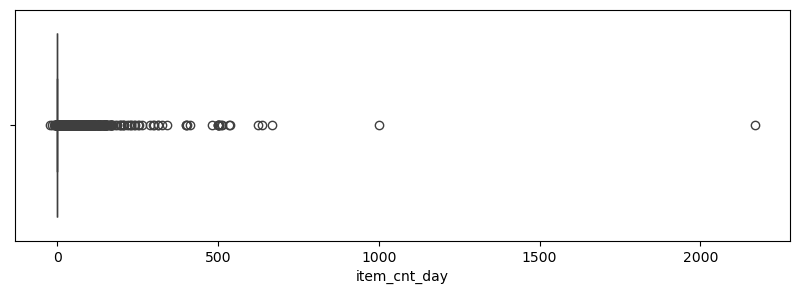

In [11]:
plt.figure(figsize=(10,3))
sns.boxplot(x=satis['item_cnt_day']);

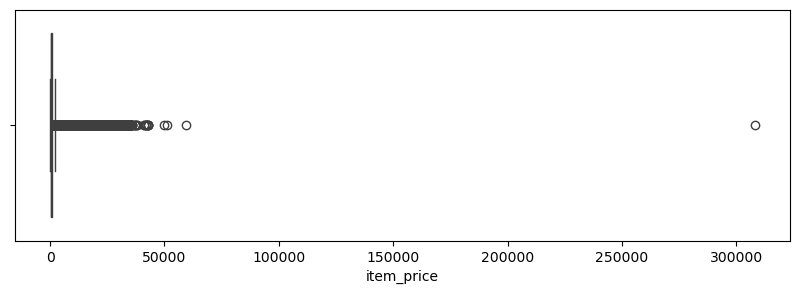

In [12]:
plt.figure(figsize=(10,3))
sns.boxplot(x=satis['item_price']);

In [13]:
print('fiyatı <=0 olan:',(satis['item_price']<=0).sum())
print('fiyatı >=100000 olan:',(satis['item_price']>=100000).sum())
print('günlük adedi >=1000 olan:',(satis['item_cnt_day']>=1000).sum())

fiyatı <=0 olan: 1
fiyatı >=100000 olan: 1
günlük adedi >=1000 olan: 2


In [14]:
satis=satis[(satis['item_price']>0)&(satis['item_price']<100000)&(satis['item_cnt_day']<1000)]

In [15]:
magazalar.loc[[0,57,1,58,10,11,39,40]]

,shop_name,shop_id
0,"!Якутск Орджоникидзе, 56 фран",0
57,"Якутск Орджоникидзе, 56",57
1,"!Якутск ТЦ ""Центральный"" фран",1
58,"Якутск ТЦ ""Центральный""",58
10,Жуковский ул. Чкалова 39м?,10
11,Жуковский ул. Чкалова 39м²,11
39,"РостовНаДону ТРК ""Мегацентр Горизонт""",39
40,"РостовНаДону ТРК ""Мегацентр Горизонт"" Островной",40


In [16]:
esle={0:57,1:58,10:11,39:40}
satis['shop_id']=satis['shop_id'].replace(esle)
test['shop_id']=test['shop_id'].replace(esle)

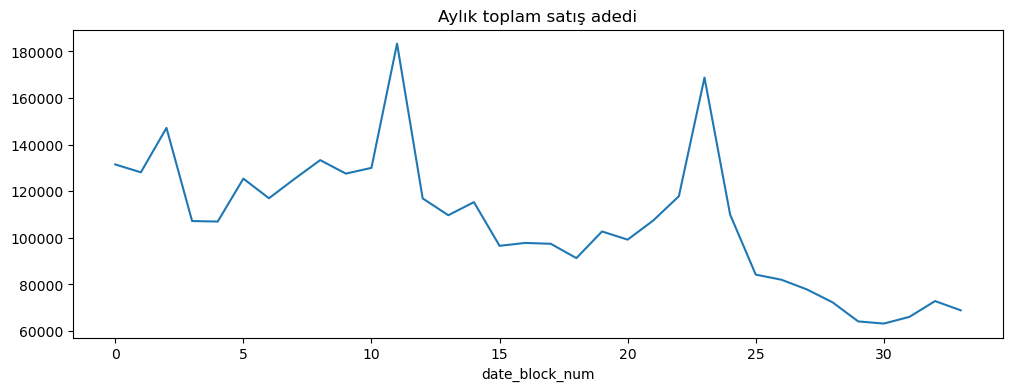

In [17]:
aylik_toplam=satis.groupby('date_block_num')['item_cnt_day'].sum()
plt.figure(figsize=(12,4))
plt.plot(aylik_toplam)
plt.title('Aylık toplam satış adedi')
plt.xlabel('date_block_num');

In [18]:
satis=satis.astype({'date_block_num':'int8','shop_id':'int8','item_id':'int32','item_price':'float32','item_cnt_day':'float32'})
aylik=satis.groupby(['date_block_num','shop_id','item_id']).agg(item_cnt_month=('item_cnt_day','sum'),fiyat=('item_price','mean')).reset_index()
aylik['item_cnt_month']=aylik['item_cnt_month'].clip(0,20)
aylik=aylik.astype({'date_block_num':'int8','shop_id':'int8','item_id':'int32','item_cnt_month':'float32','fiyat':'float32'})
aylik.shape

(1608270, 5)


Sadece satış olan satırlara bakarsak model hep "satış olur" diye öğrenir. Oysa test dosyasında satışı hiç olmayan mağaza-ürün çiftleri de var. Bu yüzden her ay için **o ay satış yapan mağazalar x o ay satılan ürünler** kombinasyonunu oluşturup satışı olmayanlara 0 yazıyoruz.

In [19]:
parcalar=[]
for ay_no in range(20,34):
    a=aylik[aylik['date_block_num']==ay_no]
    mag=a['shop_id'].unique()
    urn=a['item_id'].unique()
    g=pd.MultiIndex.from_product([mag,urn],names=['shop_id','item_id']).to_frame(index=False)
    g['date_block_num']=ay_no
    parcalar.append(g)
grid=pd.concat(parcalar,ignore_index=True)
grid=grid.astype({'date_block_num':'int8','shop_id':'int8','item_id':'int32'})
grid.shape

(3733374, 3)

In [20]:
test34=test[['shop_id','item_id']].copy()
test34['date_block_num']=34
test34=test34.astype({'date_block_num':'int8','shop_id':'int8','item_id':'int32'})
grid=pd.concat([grid,test34],ignore_index=True)
grid.shape

(3947574, 3)

In [21]:
anahtar=['date_block_num','shop_id','item_id']
grid=grid.merge(aylik[anahtar+['item_cnt_month']],on=anahtar,how='left')
grid['item_cnt_month']=grid['item_cnt_month'].fillna(0).astype('float32')
grid.loc[grid['date_block_num']==34,'item_cnt_month']=0   # bilinmiyor

In [22]:
def lag_ekle(df,kaynak,sutun,lag,yeni_ad,anahtar):
    k=kaynak[anahtar+[sutun]].copy()
    k['date_block_num']=(k['date_block_num']+lag).astype('int8')
    k=k.rename(columns={sutun:yeni_ad})
    return df.merge(k,on=anahtar,how='left')

In [23]:
for lag in [1,2,3,12]:
    grid=lag_ekle(grid,aylik,'item_cnt_month',lag,f'lag{lag}',anahtar)
grid.head()

,shop_id,item_id,date_block_num,item_cnt_month,lag1,lag2,lag3,lag12
0,2,32,20,2.0,NaN,1.0,NaN,NaN
1,2,33,20,1.0,NaN,NaN,NaN,NaN
2,2,482,20,2.0,NaN,1.0,NaN,2.0
3,2,485,20,1.0,1.0,NaN,1.0,2.0
4,2,486,20,1.0,NaN,NaN,NaN,NaN


In [24]:
urun_toplam=aylik.groupby(['date_block_num','item_id'],as_index=False)['item_cnt_month'].sum()
magaza_toplam=aylik.groupby(['date_block_num','shop_id'],as_index=False)['item_cnt_month'].sum()
urun_fiyat=aylik.groupby(['date_block_num','item_id'],as_index=False)['fiyat'].mean()

In [25]:
grid=lag_ekle(grid,urun_toplam,'item_cnt_month',1,'urun_toplam_lag1',['date_block_num','item_id'])
grid=lag_ekle(grid,magaza_toplam,'item_cnt_month',1,'magaza_toplam_lag1',['date_block_num','shop_id'])
grid=lag_ekle(grid,urun_fiyat,'fiyat',1,'fiyat_lag1',['date_block_num','item_id'])

In [26]:
grid=grid.merge(urunler[['item_id','item_category_id']],on='item_id',how='left')
grid['ay']=(grid['date_block_num']%12).astype('int8')

In [27]:
ozellikler=['shop_id','item_id','item_category_id','ay','lag1','lag2','lag3','lag12','urun_toplam_lag1','magaza_toplam_lag1','fiyat_lag1']
grid[ozellikler]=grid[ozellikler].fillna(0).astype('float32')   # geçmişi olmayanlar 0
grid.shape

(3947574, 13)

In [28]:
egitim=grid[grid['date_block_num']<33]
validation=grid[grid['date_block_num']==33]
x_train=egitim[ozellikler]
y_train=egitim['item_cnt_month']
x_val=validation[ozellikler]
y_val=validation['item_cnt_month']
print(x_train.shape,x_val.shape)

(3495202, 11) (238172, 11)


In [29]:
from sklearn.metrics import r2_score, mean_squared_error

In [30]:
def sonuc(ad,tahmin):
    tahmin=np.clip(tahmin,0,20)
    print(ad,'| R2:',round(r2_score(y_val,tahmin),4),'| RMSE:',round(np.sqrt(mean_squared_error(y_val,tahmin)),4))

In [31]:
sonuc('Geçen ay (lag1)',x_val['lag1'].values)

Geçen ay (lag1) | R2: 0.0006 | RMSE: 1.1358


In [32]:
from sklearn.linear_model import LinearRegression
L=LinearRegression()
L.fit(x_train,y_train)
Ltahmin=L.predict(x_val)
sonuc('Linear Regression',Ltahmin)

Linear Regression | R2: -0.0018 | RMSE: 1.1372


In [33]:
from sklearn.tree import DecisionTreeRegressor
d=DecisionTreeRegressor(max_depth=10,random_state=42)
d.fit(x_train,y_train)
dtahmin=d.predict(x_val)
sonuc('Decision Tree',dtahmin)

Decision Tree | R2: 0.2709 | RMSE: 0.9701


In [34]:
from sklearn.ensemble import RandomForestRegressor
ornek=egitim.sample(n=500000,random_state=42)
r=RandomForestRegressor(n_estimators=40,max_depth=12,min_samples_leaf=20,n_jobs=-1,random_state=42)
r.fit(ornek[ozellikler],ornek['item_cnt_month'])
rtahmin=r.predict(x_val)
sonuc('Random Forest',rtahmin)

Random Forest | R2: 0.2941 | RMSE: 0.9546


In [35]:
from sklearn.ensemble import HistGradientBoostingRegressor
h=HistGradientBoostingRegressor(max_iter=150,learning_rate=0.1,max_depth=8,min_samples_leaf=50,random_state=42)
h.fit(x_train,y_train)
htahmin=h.predict(x_val)
sonuc('HistGradientBoosting',htahmin)

HistGradientBoosting | R2: 0.3192 | RMSE: 0.9374


In [36]:
tablo=pd.DataFrame({
    'model':['Geçen ay (lag1)','Linear Regression','Decision Tree','Random Forest','HistGradientBoosting'],
    'RMSE':[np.sqrt(mean_squared_error(y_val,np.clip(t,0,20))) for t in [x_val['lag1'].values,Ltahmin,dtahmin,rtahmin,htahmin]]
}).sort_values('RMSE')
tablo

,model,RMSE
4,HistGradientBoosting,0.937433
3,Random Forest,0.954585
2,Decision Tree,0.970121
0,Geçen ay (lag1),1.135817
1,Linear Regression,1.137193


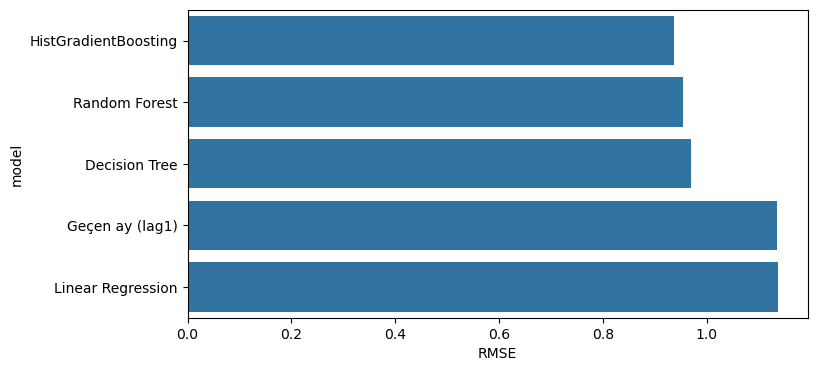

In [37]:
plt.figure(figsize=(8,4))
sns.barplot(x='RMSE',y='model',data=tablo);

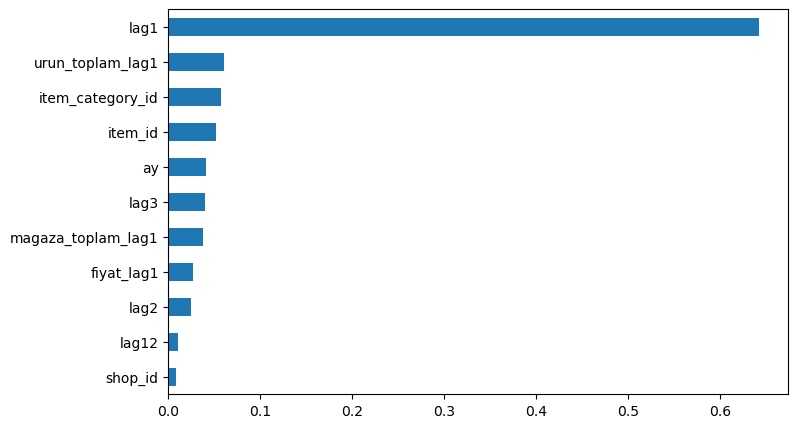

In [38]:
onem=pd.Series(r.feature_importances_,index=ozellikler).sort_values()
onem.plot(kind='barh',figsize=(8,5));

In [39]:
tum=grid[grid['date_block_num']<34]
son_model=HistGradientBoostingRegressor(max_iter=150,learning_rate=0.1,max_depth=8,min_samples_leaf=50,random_state=42)
son_model.fit(tum[ozellikler],tum['item_cnt_month'])

,loss,'squared_error'
,quantile,None
,learning_rate,0.1
,max_iter,150
,max_leaf_nodes,31
,max_depth,8
,min_samples_leaf,50
,l2_regularization,0.0
,max_features,1.0
,max_bins,255
,categorical_features,'from_dtype'


In [40]:
kasim=grid[grid['date_block_num']==34].copy()
kasim['tahmin']=np.clip(son_model.predict(kasim[ozellikler]),0,20)
kasim['shop_id']=kasim['shop_id'].astype('int16')
kasim['item_id']=kasim['item_id'].astype('int32')
kasim[['shop_id','item_id','tahmin']].head()

,shop_id,item_id,tahmin
3733374,5,5037,0.524563
3733375,5,5320,0.077482
3733376,5,5233,0.803495
3733377,5,5232,0.366483
3733378,5,5268,2.292188


In [41]:
test_id=pd.read_csv('test.csv')
test_id['shop_id']=test_id['shop_id'].replace(esle)
submission=test_id.merge(kasim[['shop_id','item_id','tahmin']].drop_duplicates(['shop_id','item_id']),on=['shop_id','item_id'],how='left')
submission=submission[['ID','tahmin']].rename(columns={'tahmin':'item_cnt_month'})
submission.to_csv('submission.csv',index=False)
submission.head()

,ID,item_cnt_month
0,0,0.524563
1,1,0.077482
2,2,0.803495
3,3,0.366483
4,4,2.292188


In [42]:
submission['item_cnt_month'].describe()

count    214200.000000
mean          0.267231
std           0.750152
min           0.000000
25%           0.040304
50%           0.083581
75%           0.216893
max          20.000000
Name: item_cnt_month, dtype: float64

In [43]:
import pickle
pickle.dump(son_model,open('satis_modeli.pkl','wb'))

In [44]:
kasim_ozellik=kasim[['shop_id','item_id']+ozellikler[2:]].drop_duplicates(['shop_id','item_id']).set_index(['shop_id','item_id'])
pickle.dump(kasim_ozellik,open('kasim_ozellik.pkl','wb'))

In [45]:
isimler={
    'magaza':dict(zip(magazalar['shop_id'],magazalar['shop_name'])),
    'urun':dict(zip(urunler['item_id'],urunler['item_name'])),
    'ozellikler':ozellikler,
}
pickle.dump(isimler,open('isimler.pkl','wb'))

Bu projede 1C Company mağazalarının günlük satış verisiyle 2015 Kasım ayı için her mağaza-ürün çiftinin satış adedini tahmin ettik. Zaman serisini, geçmiş ayların satışlarını (lag) özellik yaparak regression problemine çevirdik.En iyi sonucu HistGradientBoosting verdi (RMSE 0.937)